# Chapter 71: Bureaucracy, Public Choice, and Budget Politics

This notebook reruns four worked examples from the chapter: vote trading in a council, an expected bailout, the value of studying a ballot, and the fiscal common pool. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def signed(value, digits=2, comma=True):
    """Number for use inside a written sum: negatives get parentheses, '(-5.00)'."""
    text = num(value, digits, comma)
    return f"({text})" if text.startswith("-") else text


def logroll_payoffs(benefit, tax):
    """Three-member council, two projects (A's and B's), each costing every district `tax` and giving its host `benefit`.

    Principle: logrolling. Book (ch071): benefit 9, tax 2 gives (7, -2, -2) per project, Delta V_A = 7 - 2 = 5,
    Delta V_B = 5, Delta V_C = -4, Delta W = 6; tax 4 gives 1, 1, -8 and -6.
    The trade is accepted when both traders gain (a zero gain is reported as indifference).
    """
    host = benefit - tax
    trader = host - tax
    outsider = -2 * tax
    return {"host": host, "other": -tax, "dV_A": trader, "dV_B": trader, "dV_C": outsider,
            "dW": 2 * trader + outsider, "accepted": trader > 0, "indifferent": trader == 0}


def soft_budget(p_weak, bailout, strong=180.0, weak=80.0, cost=140.0, basic=10.0):
    """Large plan under an expected bailout in the weak state (capped at the weak-state loss).

    Principle: soft-budget-constraint. Book (ch071): p = 0.5, bailout 50 gives true value
    0.5(40) + 0.5(-60) = -10, perceived 0.5(40) + 0.5(-10) = 15 > 10 (large plan chosen) and
    treasury exposure 0.5 x 50 = 25; bailout 0 gives -10 < 10 (basic plan).
    """
    loss = cost - weak
    paid = min(bailout, max(loss, 0.0))
    good, bad = strong - cost, weak - cost
    true_value = (1 - p_weak) * good + p_weak * bad
    perceived = (1 - p_weak) * good + p_weak * (bad + paid)
    return {"good": good, "bad": bad, "paid": paid, "bad_perceived": bad + paid, "true": true_value,
            "perceived": perceived, "basic": basic, "exposure": p_weak * paid}


def rational_ignorance(p, B, d, cost):
    """Net private return to studying a ballot question: p B + d - cost.

    Principle: rational-ignorance. Book (ch071): cost 3 x 18 = 54, B = 600, p = 1/200,000 gives pB = 0.003 and
    net -53.997; p = 0.10 gives 60 - 54 = 6; d = 70 gives 0.003 + 70 > 54.
    """
    benefit = p * B + d
    return {"pB": p * B, "benefit": benefit, "net": benefit - cost, "study": benefit > cost}


def fiscal_common_pool(n, benefit, cost=10.0):
    """Shared-finance district project: perceived gain benefit - cost/n against true net benefit - cost.

    Principle: fiscal-common-pool-problem. Book (ch071): n = 5, benefit 6, cost 10 ($ million) gives
    exposure 2, perceived gain 4, all five pass, each district pays 5 x 2 = 10 and ends at -4; aggregate
    benefit 30, cost 50, surplus -20. A district-specific levy (n = 1) gives 6 - 10 = -4: not proposed.
    """
    share = cost / n
    perceived = benefit - share
    proposed = perceived > 0
    passed = n if proposed else 0
    return {"share": share, "perceived": perceived, "true_net": benefit - cost, "proposed": proposed,
            "passed": passed, "benefit_all": passed * benefit, "cost_all": passed * cost,
            "paid_per_district": passed * share, "final_position": benefit - cost if proposed else 0.0,
            "aggregate": passed * (benefit - cost)}


plt.rcParams.update(HOUSE_RC)


games = SimpleNamespace(logroll_payoffs=logroll_payoffs)


information = SimpleNamespace(soft_budget=soft_budget)


public = SimpleNamespace(rational_ignorance=rational_ignorance, fiscal_common_pool=fiscal_common_pool)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'logrolling': {'benefit': 9,
                'tax': 2,
                'host': 7,
                'dV_A': 5,
                'dV_B': 5,
                'dV_C': -4,
                'dW': 6,
                'tax_high': 4,
                'host_high': 5,
                'dV_A_high': 1,
                'dV_C_high': -8,
                'dW_high': -6},
 'soft-budget-constraint': {'basic': 10,
                            'cost': 140,
                            'strong': 180,
                            'weak': 80,
                            'p_weak': 0.5,
                            'true': -10,
                            'bailout': 50,
                            'bad_perceived': -10,
                            'perceived': 15,
                            'exposure': 25},
 'rational-ignorance': {'hours': 3,
                        'wage': 18,
                        'cost': 54,
                        'B': 600,
                        'p': 5e-06,
                        'pB': 0.003,
                        'net': -53.997,
                        'p_committee': 0.1,
                        'pB_committee': 60,
                        'net_committee': 6,
                        'd': 70},
 'fiscal-common-pool-problem': {'n': 5,
                                'benefit': 6,
                                'cost': 10,
                                'true_net': -4,
                                'benefit_all': 30,
                                'cost_all': 50,
                                'aggregate': -20,
                                'share': 2,
                                'perceived': 4,
                                'paid': 10,
                                'final_position': -4},
 'constructed': {'logrolling': {'tax': [3], 'benefit': [6, 12]},
                 'soft-budget-constraint': {'bailout': [30, 60], 'p_weak': [0.3, 0.7]},
                 'rational-ignorance': {'p': [0.01], 'd': [30]},
                 'fiscal-common-pool-problem': {'n': [2, 10], 'benefit': [4, 12]}}}


def sign_color(v):
    return "teal" if v > 0 else ("terracotta" if v < 0 else "grey")


def logroll_picture(tax=2, benefit=9):
    r = games.logroll_payoffs(benefit, tax)
    fig, ax = new_figure()
    names = ["District A", "District B", "District C", "Total"]
    vals = [r["dV_A"], r["dV_B"], r["dV_C"], r["dW"]]
    bar_compare(ax, names, vals, colors=[sign_color(v) for v in vals], value_labels=[num(v, 0) for v in vals],
                ylabel="Payoff from the two-project package", xlabel="Member")
    ax.set_ylim(-26, 22)
    if r["accepted"]:
        deal = "both traders gain, so the trade is accepted"
        short = "Yes"
    elif r["indifferent"]:
        deal = "the traders gain nothing, so they are indifferent to the trade"
        short = "Indifferent"
    else:
        deal = "the traders would lose, so no trade is made"
        short = "No"
    if r["dW"] > 0:
        welfare = "the package creates aggregate surplus"
    elif r["dW"] < 0:
        welfare = "the package destroys aggregate surplus"
    else:
        welfare = "the package exactly breaks even for the council as a whole"
    metrics = {"Host's own project": num(r["host"], 0), "Delta V_A": num(r["dV_A"], 0), "Delta V_B": num(r["dV_B"], 0),
               "Delta V_C": num(r["dV_C"], 0), "Delta W": num(r["dW"], 0), "Trade accepted": short}
    steps = [f"Each project: host {benefit} - {tax} = {num(r['host'], 0)}, others -{tax}",
             f"Delta V_A = {num(r['host'], 0)} - {tax} = {num(r['dV_A'], 0)}; Delta V_B = -{tax} + {num(r['host'], 0)} = "
             f"{num(r['dV_B'], 0)}",
             f"Delta V_C = -{tax} - {tax} = {num(r['dV_C'], 0)}",
             f"Delta W = {num(r['dV_A'], 0)} + {signed(r['dV_B'], 0)} + {signed(r['dV_C'], 0)} = {num(r['dW'], 0)}"]
    interp = (f"Separately each project fails two to one, since only its host gains {benefit} - {tax} = "
              f"{num(r['host'], 0)}. In the package A and B each get {num(r['host'], 0)} - {tax} = {num(r['dV_A'], 0)}, "
              f"so {deal}; C pays for both and gets {num(r['dV_C'], 0)}. In total {welfare}: Delta W = "
              f"{num(r['dW'], 0)}.")
    alt = (f"Bars of package payoffs: A {num(r['dV_A'], 0)}, B {num(r['dV_B'], 0)}, C {num(r['dV_C'], 0)} and "
           f"total {num(r['dW'], 0)}, with host benefit {benefit} and tax cost {tax} per project.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def soft_budget_picture(bailout=50, pweak=0.5):
    r = information.soft_budget(pweak, bailout)
    ps = 1 - pweak
    fig, ax = new_figure()
    names = ["Basic plan", "Large plan, perceived", "Large plan, true"]
    vals = [r["basic"], r["perceived"], r["true"]]
    bar_compare(ax, names, vals, colors=["grey", sign_color(r["perceived"] - r["basic"]), "navy"],
                value_labels=[num(v, 2) for v in vals], ylabel="Expected net value", xlabel="Option")
    hline(ax, r["basic"], col="grey")
    ax.set_ylim(-35, 40)
    if r["perceived"] > r["basic"]:
        choice, short = "the large plan", "Large"
    elif r["perceived"] < r["basic"]:
        choice, short = "the basic plan", "Basic"
    else:
        choice, short = "either plan: the operator is indifferent (a tie)", "Tie"
    metrics = {"True large-plan value": num(r["true"]), "Perceived large-plan value": num(r["perceived"]),
               "Basic plan": num(r["basic"]), "Chosen plan": short, "Treasury exposure": num(r["exposure"])}
    steps = [f"True: {num(ps, 1)} x 40 + {num(pweak, 1)} x (-60) = {num(r['true'])}",
             f"Weak state with bailout {num(r['paid'], 0)}: 80 - 140 + {num(r['paid'], 0)} = {num(r['bad_perceived'], 0)}",
             f"Perceived: {num(ps, 1)} x 40 + {num(pweak, 1)} x {signed(r['bad_perceived'], 0)} = {num(r['perceived'])}",
             f"Exposure: {num(pweak, 1)} x {num(r['paid'], 0)} = {num(r['exposure'])}"]
    cap = (f" The expected bailout of {bailout} exceeds the weak-state loss of 60, so only 60 is paid."
           if bailout > 60 else "")
    interp = (f"Under a hard budget the large plan is worth {num(ps, 1)} x 40 + {num(pweak, 1)} x (-60) = "
              f"{num(r['true'])}. With the expected bailout the operator sees {num(ps, 1)} x 40 + {num(pweak, 1)} x "
              f"{signed(r['bad_perceived'], 0)} = {num(r['perceived'])} against the basic plan's 10, so it chooses "
              f"{choice}. Expected treasury exposure is {num(r['exposure'])}.{cap}")
    alt = (f"Bars: basic plan 10, large plan perceived {num(r['perceived'])} and true {num(r['true'])}, with weak "
           f"demand probability {num(pweak, 1)} and bailout {bailout}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


PIVOTS = {"tiny": (1 / 200_000, "1/200,000"), "pct1": (0.01, "0.01"), "pct10": (0.10, "0.10")}


def ignorance_picture(pivot="tiny", reuse=0):
    p, ptxt = PIVOTS[pivot]
    b = BV["rational-ignorance"]
    r = public.rational_ignorance(p, b["B"], reuse, b["cost"])
    fig, ax = new_figure()
    ax.bar([0], [r["pB"]], width=0.5, color=PALETTE["teal"])
    ax.bar([0], [reuse], bottom=[r["pB"]], width=0.5, color=PALETTE["gold"])
    ax.bar([1], [b["cost"]], width=0.5, color=PALETTE["terracotta"])
    ax.annotate(tex_safe(money(r["benefit"], 3)), (0, r["benefit"]), xytext=(0, 4), textcoords="offset points",
                ha="center", va="bottom", fontsize=10.5)
    ax.annotate("$54", (1, 54), xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=10.5)
    ax.set_xticks([0, 1], ["Expected benefit", "Cost of study"])
    ax.text(0.03, 0.97, tex_safe(f"teal: pB = {money(r['pB'], 3)}"), transform=ax.transAxes, ha="left", va="top",
            fontsize=10.5, color=PALETTE["teal"])
    ax.text(0.03, 0.89, tex_safe(f"gold: reusable value d = {money(reuse, 0)}"), transform=ax.transAxes, ha="left",
            va="top", fontsize=10.5, color=PALETTE["gold"])
    ax.set_xlim(-0.6, 1.6)
    ax.set_ylim(0, 165)
    ax.set_ylabel("Dollars")
    ax.set_xlabel("Comparison")
    study = r["study"]
    metrics = {"Cost of study": "$54.00", "Expected pivotal benefit pB": money(r["pB"], 3),
               "Reusable value d": money(reuse, 0), "Net return": money(r["net"], 3),
               "Decision": "Study" if study else "Stay uninformed"}
    steps = ["c = 3 x 18 = 54",
             f"pB = {ptxt} x 600 = {num(r['pB'], 3)}",
             f"Net = {num(r['pB'], 3)} + {reuse} - 54 = {num(r['net'], 3)}",
             "Net return is positive, so study" if study else "Net return is negative, so stay uninformed"]
    interp = (f"Study costs 3 x 18 = 54 dollars. With a {ptxt} chance of deciding, the expected pivotal benefit is "
              f"{ptxt} x 600 = {money(r['pB'], 3)}; adding reusable value {money(reuse, 0)} gives "
              f"{money(r['benefit'], 3)}, so the net return is {money(r['net'], 3)} and the resident "
              f"{'studies' if study else 'stays uninformed'}.")
    alt = (f"Bar of expected benefit {money(r['benefit'], 3)} (pivotal {money(r['pB'], 3)} plus reusable "
           f"{money(reuse, 0)}) beside the $54 cost.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def common_pool_picture(n=5, benefit=6):
    r = public.fiscal_common_pool(n, benefit, 10)
    fig, (ax1, ax2) = new_figure(ncols=2)
    vals = [r["perceived"], r["true_net"]]
    bar_compare(ax1, ["Perceived gain", "True net value"], vals, colors=[sign_color(v) for v in vals],
                value_labels=[num(v, 0) for v in vals], ylabel="Per project ($ million)", xlabel="View")
    ax1.set_ylim(-11, 14)
    vals2 = [r["benefit_all"], r["cost_all"], r["aggregate"]]
    bar_compare(ax2, ["Benefit", "Cost", "Surplus"], vals2, colors=["teal", "terracotta", sign_color(r["aggregate"])],
                value_labels=[num(v, 0) for v in vals2], ylabel="All passed projects ($ million)", xlabel="Total")
    ax2.set_ylim(-85, 140)
    nd = "district" if n == 1 else "districts"
    passed = r["passed"]
    proj = "project" if passed == 1 else "projects"
    metrics = {"Own cost share ($M)": num(r["share"]), "Perceived gain ($M)": num(r["perceived"]),
               "Projects passed": str(passed), "District final position ($M)": num(r["final_position"]),
               "Aggregate surplus ($M)": num(r["aggregate"])}
    steps = [f"Cost share = 10 / {n} = {num(r['share'])}",
             f"Perceived gain = {benefit} - {num(r['share'])} = {num(r['perceived'])}",
             f"True net = {benefit} - 10 = {num(r['true_net'], 0)}",
             f"Aggregate = {passed} x ({benefit} - 10) = {num(r['aggregate'], 0)}"]
    if r["proposed"]:
        passes = ("so the representative proposes and the project passes" if passed == 1
                  else f"so every representative proposes and all {passed} {proj} pass")
        out = (f"{passes}. Each district gets {benefit} but pays "
               f"{passed} x {num(r['share'])} = {num(r['paid_per_district'])}, ending at {num(r['final_position'])}")
    else:
        out = "so no representative proposes the project and spending on this set stays at zero"
    tv = ("the project is worth more than it costs" if r["true_net"] > 0 else "each project costs more than it is worth")
    who = "With a district-specific levy" if n == 1 else f"With {n} {nd} sharing finance"
    interp = (f"{who}, a sponsor pays 10 / {n} = {num(r['share'])} million of its own "
              f"project and sees a gain of {benefit} - {num(r['share'])} = {num(r['perceived'])} million, {out}. "
              f"In truth {tv}: {benefit} - 10 = {num(r['true_net'], 0)} million per project, so aggregate surplus is "
              f"{num(r['aggregate'], 0)} million.")
    alt = (f"Left: perceived gain {num(r['perceived'])} against true value {num(r['true_net'], 0)} per project. Right: "
           f"benefit {num(r['benefit_all'], 0)}, cost {num(r['cost_all'], 0)} and surplus {num(r['aggregate'], 0)} "
           f"for {passed} passed {proj}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Logrolling: vote trading in a three-member council

Each project gives its host 9 and costs every district 2.

$$\Delta V_A=7-2=5, \qquad \Delta W=5+5-4=6$$

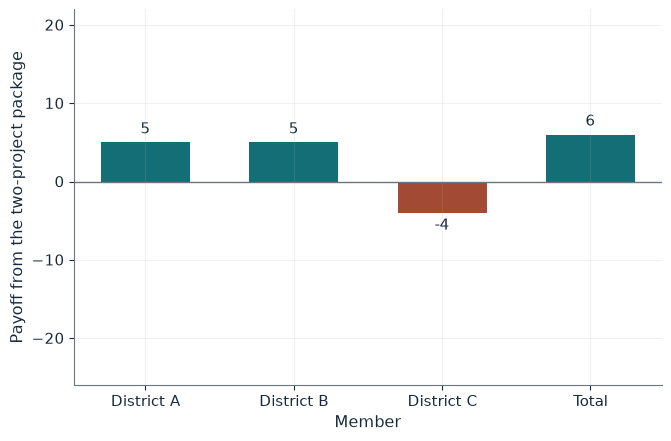

Host's own project  7
Delta V_A           5
Delta V_B           5
Delta V_C           -4
Delta W             6
Trade accepted      Yes

Worked steps:
  1. Each project: host 9 - 2 = 7, others -2
  2. Delta V_A = 7 - 2 = 5; Delta V_B = -2 + 7 = 5
  3. Delta V_C = -2 - 2 = -4
  4. Delta W = 5 + 5 + (-4) = 6

Separately each project fails two to one, since only its host gains 9 - 2 = 7. In the package A and B each get 7 - 2 = 5, so both traders gain, so the trade is accepted; C pays for both and gets -4. In total the package creates aggregate surplus: Delta W = 6.


In [2]:
show(logroll_picture(tax=2, benefit=9))

Change one input, `tax`, and hold the others at the book's values:

In [3]:
sweep(logroll_picture, 'tax', [2, 3, 4], {'benefit': 9}, ['Delta V_A', 'Delta V_C', 'Delta W', 'Trade accepted'])

tax | Delta V_A | Delta V_C | Delta W | Trade accepted
2 | 5 | -4 | 6 | Yes
3 | 3 | -6 | 0 | Yes
4 | 1 | -8 | -6 | Yes


The trade creates 6 units of surplus at a tax of 2, breaks even at 3, and destroys 6 at 4, yet the two traders gain in every case shown: reciprocal gain is not a welfare test.

## 2. Soft budget constraint: expected bailouts change the plan

The large plan costs 140 and yields 180 or 80 with equal odds; the basic plan nets 10.

$$0.5(180-140)+0.5(80-140)=-10, \qquad 0.5(40)+0.5(-10)=15$$

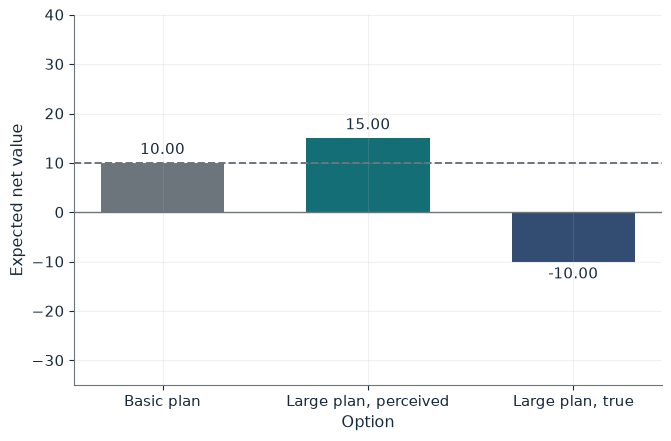

True large-plan value       -10.00
Perceived large-plan value  15.00
Basic plan                  10.00
Chosen plan                 Large
Treasury exposure           25.00

Worked steps:
  1. True: 0.5 x 40 + 0.5 x (-60) = -10.00
  2. Weak state with bailout 50: 80 - 140 + 50 = -10
  3. Perceived: 0.5 x 40 + 0.5 x (-10) = 15.00
  4. Exposure: 0.5 x 50 = 25.00

Under a hard budget the large plan is worth 0.5 x 40 + 0.5 x (-60) = -10.00. With the expected bailout the operator sees 0.5 x 40 + 0.5 x (-10) = 15.00 against the basic plan's 10, so it chooses the large plan. Expected treasury exposure is 25.00.


In [4]:
show(soft_budget_picture(bailout=50, pweak=0.5))

Change one input, `bailout`, and hold the others at the book's values:

In [5]:
sweep(soft_budget_picture, 'bailout', [0, 30, 50, 60], {'pweak': 0.5}, ['Perceived large-plan value', 'Chosen plan', 'Treasury exposure'])

bailout | Perceived large-plan value | Chosen plan | Treasury exposure
0 | -10.00 | Basic | 0.00
30 | 5.00 | Basic | 15.00
50 | 15.00 | Large | 25.00
60 | 20.00 | Large | 30.00


A bailout of 50 makes the large plan look worth 15, above 10, though its true value is -10; expected treasury exposure is 25. The operator is indifferent at a bailout of 40.

## 3. Rational ignorance: when is studying the ballot worth it?

Study costs 3 hours at \$18 and the stake is \$600.

$$pB=\frac{1}{200{,}000}\times\$600=\$0.003$$

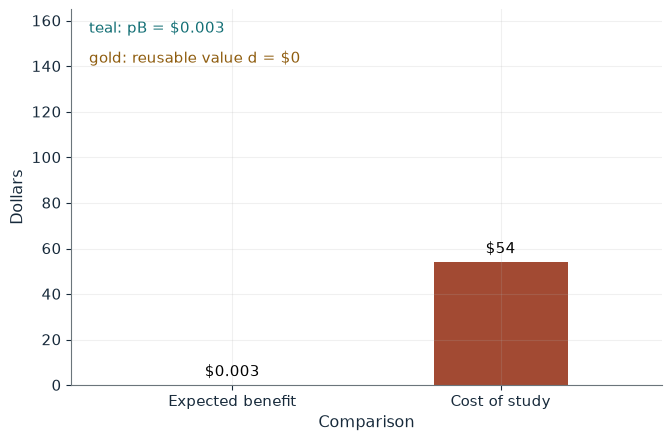

Cost of study                $54.00
Expected pivotal benefit pB  $0.003
Reusable value d             $0
Net return                   -$53.997
Decision                     Stay uninformed

Worked steps:
  1. c = 3 x 18 = 54
  2. pB = 1/200,000 x 600 = 0.003
  3. Net = 0.003 + 0 - 54 = -53.997
  4. Net return is negative, so stay uninformed

Study costs 3 x 18 = 54 dollars. With a 1/200,000 chance of deciding, the expected pivotal benefit is 1/200,000 x 600 = $0.003; adding reusable value $0 gives $0.003, so the net return is -$53.997 and the resident stays uninformed.


In [6]:
show(ignorance_picture(pivot='tiny', reuse=0))

Change one input, `pivot`, and hold the others at the book's values:

In [7]:
sweep(ignorance_picture, 'pivot', ['tiny', 'pct1', 'pct10'], {'reuse': 0}, ['Expected pivotal benefit pB', 'Net return', 'Decision'])

pivot | Expected pivotal benefit pB | Net return | Decision
tiny | $0.003 | -$53.997 | Stay uninformed
pct1 | $6.000 | -$48.000 | Stay uninformed
pct10 | $60.000 | $6.000 | Study


In a large election the net return is -\$53.997, so ignorance is rational. On a committee with a 0.10 chance of deciding the benefit is \$60 and study pays; reusable value of \$70 also tips it.

## 4. Fiscal common pool: everyone's project, no one's bill

Five districts share finance; each project costs \$10 million and gives its district \$6 million.

$$\frac{1}{5}\times\$10=\$2\text{ million}$$

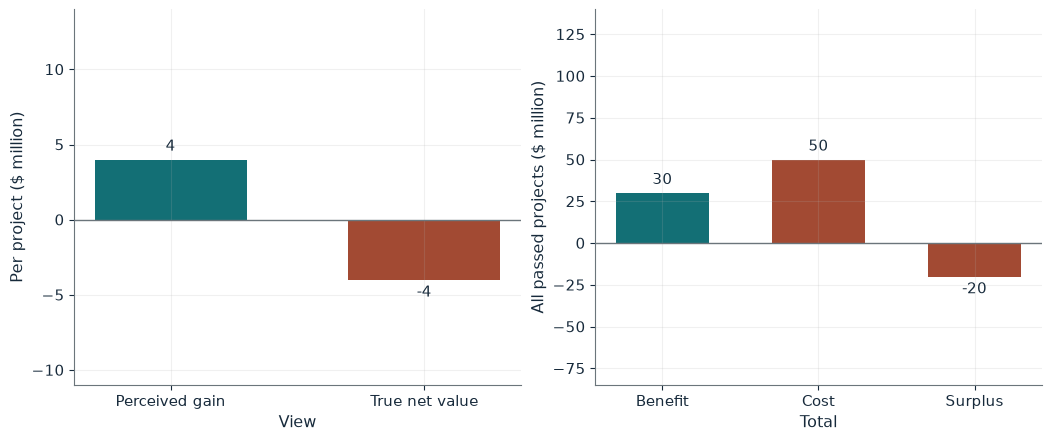

Own cost share ($M)           2.00
Perceived gain ($M)           4.00
Projects passed               5
District final position ($M)  -4.00
Aggregate surplus ($M)        -20.00

Worked steps:
  1. Cost share = 10 / 5 = 2.00
  2. Perceived gain = 6 - 2.00 = 4.00
  3. True net = 6 - 10 = -4
  4. Aggregate = 5 x (6 - 10) = -20

With 5 districts sharing finance, a sponsor pays 10 / 5 = 2.00 million of its own project and sees a gain of 6 - 2.00 = 4.00 million, so every representative proposes and all 5 projects pass. Each district gets 6 but pays 5 x 2.00 = 10.00, ending at -4.00. In truth each project costs more than it is worth: 6 - 10 = -4 million per project, so aggregate surplus is -20 million.


In [8]:
show(common_pool_picture(n=5, benefit=6))

Change one input, `n`, and hold the others at the book's values:

In [9]:
sweep(common_pool_picture, 'n', [1, 2, 5, 10], {'benefit': 6}, ['Perceived gain ($M)', 'Projects passed', 'Aggregate surplus ($M)'])

n | Perceived gain ($M) | Projects passed | Aggregate surplus ($M)
1 | -4.00 | 0 | 0.00
2 | 1.00 | 2 | -8.00
5 | 4.00 | 5 | -20.00
10 | 5.00 | 10 | -40.00


Each sponsor sees 6 - 2 = 4 and all five projects pass, leaving every district at -4 and the federation at -20. With a district-specific levy (one district) nobody proposes.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

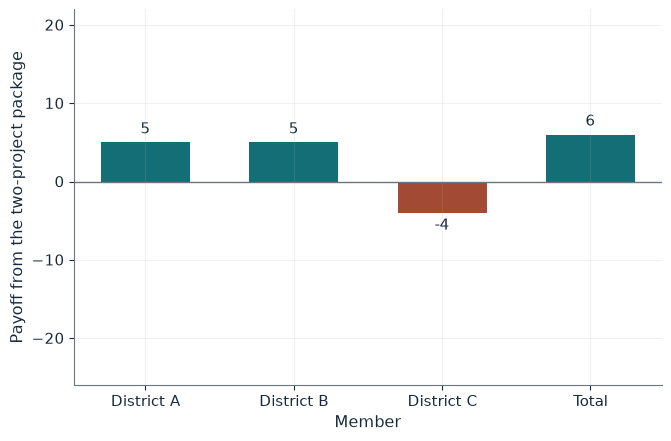

Host's own project  7
Delta V_A           5
Delta V_B           5
Delta V_C           -4
Delta W             6
Trade accepted      Yes

Worked steps:
  1. Each project: host 9 - 2 = 7, others -2
  2. Delta V_A = 7 - 2 = 5; Delta V_B = -2 + 7 = 5
  3. Delta V_C = -2 - 2 = -4
  4. Delta W = 5 + 5 + (-4) = 6

Separately each project fails two to one, since only its host gains 9 - 2 = 7. In the package A and B each get 7 - 2 = 5, so both traders gain, so the trade is accepted; C pays for both and gets -4. In total the package creates aggregate surplus: Delta W = 6.


In [10]:
show(logroll_picture(tax=2, benefit=9))

## Practice

**1.** With host benefit 9 and tax cost 3, what are coalition and total payoffs?

<details><summary>Answer</summary>

Each trader gets 6 - 3 = 3, C loses 6, total 3 + 3 - 6 = 0.

</details>

**2.** With bailout 30 and weak probability 0.5, which plan is chosen?

<details><summary>Answer</summary>

0.5 x 40 + 0.5 x (-30) = 5 < 10, so the basic plan.

</details>

**3.** With 10 districts and benefit \$4M, what is the aggregate surplus if all pass?

<details><summary>Answer</summary>

Perceived 4 - 1 = 3 > 0, so all pass; aggregate 10 x (4 - 10) = -\$60 million.

</details>